# GNN 266 Phase3 — SimpleConcat + 4-layer HeteroGAT + Margin Loss

phase3_patent_faiss.ipynb **실험 2 (SimpleConcat)** 구조를 266건 소송 데이터에 적용.

## phase3 실험 2 핵심 설계

| 항목 | v2 (이전) | phase3 실험 2 (이번) |
|------|-----------|----------------------|
| Patent 투영 | Linear(1024→256) | **SimpleConcat**: cat(3d, 1024d) → Linear(1027→128) |
| Company 피처 | Learnable embedding | **FAISS avg** → Linear(1024→128) |
| sued edges | 그래프 제외 | **train sued edges 포함** (transductive) |
| GAT layers | 3 (HID=256, OUT=128) | **4 (HID=128, OUT=64)** heads: 8→4→4→2 |
| Norm | LayerNorm | **BatchNorm1d** (L1~L3 뒤만) |
| Act | ReLU | L1/L2: LeakyReLU  **L3: Tanh**  L4: none |
| Loss | InfoNCE | **Margin(dot product)** margin=1.0 |
| Negatives | whole-dataset | **PerSourceUniform k=4** (random) |


In [1]:
# Cell 1 — Imports
import subprocess, sys, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import faiss
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from collections import defaultdict

try:
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, GATConv
    print('PyG OK:', torch_geometric.__version__)
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch_geometric', '-q'])
    import torch_geometric
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, GATConv

warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}  |  PyTorch: {torch.__version__}')

PyG OK: 2.8.0
Device: cuda  |  PyTorch: 2.6.0+cu124


In [2]:
# Cell 2 — Paths
ROOT = Path('../..').resolve()
SRC  = ROOT / 'src'
DATA = ROOT / 'data' / 'samples'

FAISS_INDEX = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/faiss.index')
PATENT_IDX  = Path('/home2/jmbyeon/developments/scratch/patent_eval/uspto_db/data/embeddings/patent_index.parquet')

print('ROOT :', ROOT)
print('FAISS:', FAISS_INDEX.exists(), '| patent_index:', PATENT_IDX.exists())

ROOT : /home2/jmbyeon/developments/tf_litigation/MANTF-master
FAISS: True | patent_index: True


In [3]:
# Cell 3 — Raw data + company normalization
_SUFFIX = re.compile(
    r',?\s*('
    r'incorporated|corporation|company|limited liability company'
    r'|limited liability partnership|limited partnership|limited'
    r'|inc|corp|co|ltd|llc|llp|lp|plc|gmbh|b\.?v|n\.?v|s\.?a|a\.?g|s\.?r\.?l'
    r'|pvt|pte|pty|ab|as|a\/s|oy|oyj|spa|srl|sarl|sas|bv|nv'
    r'|an? (?:delaware|california|new\s+york|new\s+jersey|texas|illinois|florida'
    r'|washington|ohio|michigan|minnesota|pennsylvania|nevada|maryland|virginia'
    r'|massachusetts|colorado|georgia|indiana|wisconsin|arizona|connecticut'
    r'|netherlands|korean?|japanese|german|french|canadian|british|swedish|swiss)'
    r'\s+(?:corporation|limited\s+liability(?:\s+company)?|limited\s+partnership|limited|company)'
    r'|doing business as|terminated.*'
    r')[,.]?\s*$',
    re.IGNORECASE
)
_PREFIX = re.compile(r'^(the|a|an)\s+', re.IGNORECASE)
_JUNK   = re.compile(r'^(does |john doe|unknown|xyz |consolidated civil|et al)', re.IGNORECASE)

def deep_normalize(name):
    s = str(name).strip().replace('&', 'and')
    s = re.sub(r'[^\w\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip().upper()
    for _ in range(6):
        new = _SUFFIX.sub('', s, count=1).strip()
        if new == s: break
        s = new
    return _PREFIX.sub('', s).strip()

_mm_path = DATA / 'company_merge_map.csv'
MERGE_MAP = {}
if _mm_path.exists():
    _mm = pd.read_csv(_mm_path)
    MERGE_MAP = dict(zip(_mm['from'], _mm['to']))

def canonical(name):
    n = deep_normalize(name)
    return MERGE_MAP.get(n, n)

def parse_pipe(s):
    if pd.isna(s): return []
    return [x.strip() for x in str(s).split('|') if x.strip()]

raw = pd.read_csv(DATA / 'both_side_patents.csv')

rows = []
for _, r in raw.iterrows():
    for pat in parse_pipe(r['P_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'plaintiff'})
    for pat in parse_pipe(r['D_patents']):
        rows.append({'case_row_id': r['case_row_id'], 'patent_id': pat, 'side': 'defendant'})
df_pats = pd.DataFrame(rows)
ALL_PATENTS = set(df_pats['patent_id'].unique())

company_rows = []
for _, r in raw.iterrows():
    for name in parse_pipe(r['plaintiffs']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'plaintiff'})
    for name in parse_pipe(r['defendants']):
        cn = canonical(name)
        if cn and not _JUNK.match(cn) and len(cn) > 2:
            company_rows.append({'case_row_id': r['case_row_id'], 'norm_name': cn, 'side': 'defendant'})
df_companies = pd.DataFrame(company_rows)
litigation_companies = set(df_companies['norm_name'])

print(f'Cases  : {raw["case_row_id"].nunique()}')
print(f'Patents: {len(ALL_PATENTS)}')
print(f'Companies: {len(litigation_companies)}')

Cases  : 269
Patents: 1331
Companies: 1062


In [4]:
# Cell 4 — IPC / Citation / Assignee
ipc_raw = pd.read_csv(SRC / 'g_ipc_at_issue.tsv', sep='\t',
                      usecols=['patent_id', 'section', 'ipc_class', 'subclass'], dtype=str)
ipc_raw['patent_id'] = ipc_raw['patent_id'].str.strip()
df_ipc = ipc_raw[ipc_raw['patent_id'].isin(ALL_PATENTS)].copy()
df_ipc['ipc_code'] = (df_ipc['section'].fillna('') +
                      df_ipc['ipc_class'].fillna('') +
                      df_ipc['subclass'].fillna('')).str.strip()
df_ipc = df_ipc[df_ipc['ipc_code'] != ''].drop_duplicates(['patent_id', 'ipc_code'])

cit_raw = pd.read_csv(SRC / 'g_us_patent_citation.tsv', sep='\t',
                      usecols=['patent_id', 'citation_patent_id'], dtype=str)
cit_raw['patent_id']          = cit_raw['patent_id'].str.strip()
cit_raw['citation_patent_id'] = cit_raw['citation_patent_id'].str.strip()
df_cit = cit_raw[
    cit_raw['patent_id'].isin(ALL_PATENTS) &
    cit_raw['citation_patent_id'].isin(ALL_PATENTS)
].drop_duplicates().copy()

own_raw = pd.read_csv(DATA / 'patent_ownership_matched_4.csv',
                      usecols=['patent_norm', 'final_owner'], dtype=str).dropna()
own_raw['org_norm'] = own_raw['final_owner'].apply(canonical)
df_asgn = own_raw[
    own_raw['patent_norm'].isin(ALL_PATENTS) &
    (own_raw['org_norm'].str.len() > 2)
].drop_duplicates(['patent_norm', 'org_norm']
).rename(columns={'patent_norm': 'patent_id'})[['patent_id', 'org_norm']]

print(f'IPC   : {df_ipc["ipc_code"].nunique()} codes, {len(df_ipc)} edges')
print(f'Cites : {len(df_cit)} edges')
print(f'Owns  : {len(df_asgn)} edges')

IPC   : 218 codes, 1545 edges
Cites : 803 edges
Owns  : 1396 edges


In [5]:
# Cell 5 — FAISS embeddings (L2 normalized)
_index     = faiss.read_index(str(FAISS_INDEX))
_pidx      = pd.read_parquet(PATENT_IDX)
pid_to_fid = dict(zip(_pidx['patent_id'].astype(str).str.strip(), _pidx['faiss_id']))

pat_list   = sorted(ALL_PATENTS)
pat_to_idx = {p: i for i, p in enumerate(pat_list)}
idx_to_pid = {i: p for p, i in pat_to_idx.items()}

FAISS_DIM = 1024
pat_emb   = np.zeros((len(pat_list), FAISS_DIM), dtype=np.float32)
for i, pid in enumerate(pat_list):
    if pid in pid_to_fid:
        pat_emb[i] = _index.reconstruct(int(pid_to_fid[pid]))

norms   = np.linalg.norm(pat_emb, axis=1, keepdims=True)
pat_emb = pat_emb / np.maximum(norms, 1e-8)

print(f'Patent FAISS: {pat_emb.shape}  (L2 normalized)')

Patent FAISS: (1331, 1024)  (L2 normalized)


In [6]:
# Cell 6 — Structural features (3d) + Company FAISS avg features
#
# [phase3 핵심 1] Struct 피처
#   phase3는 18d (SK, PPS, ET, ...) 사용
#   여기서는 그래프에서 직접 계산 가능한 3d 사용
#     n_ipc      : IPC 코드 수
#     n_cites_out: 소송특허 간 citation 수 (출)
#     n_cites_in : 소송특허 간 citation 수 (입)

ipc_count  = df_ipc.groupby('patent_id').size().to_dict()
cit_out    = df_cit.groupby('patent_id').size().to_dict()
cit_in     = df_cit.groupby('citation_patent_id').size().to_dict()

STRUCT_DIM = 3
pat_struct = np.zeros((len(pat_list), STRUCT_DIM), dtype=np.float32)
for i, pid in enumerate(pat_list):
    pat_struct[i, 0] = ipc_count.get(pid, 0)
    pat_struct[i, 1] = cit_out.get(pid, 0)
    pat_struct[i, 2] = cit_in.get(pid, 0)

pat_struct = StandardScaler().fit_transform(pat_struct).astype(np.float32)
print(f'Patent struct: {pat_struct.shape}  (n_ipc, cites_out, cites_in — StandardScaled)')
print(f'  n_ipc  mean={ipc_count and np.mean(list(ipc_count.values())):.1f}')
print(f'  cit_out mean={cit_out and np.mean(list(cit_out.values())):.1f}')
print(f'  cit_in  mean={cit_in and np.mean(list(cit_in.values())):.1f}')

# [phase3 핵심 2] Company FAISS avg
#   소유 특허들의 FAISS 임베딩 평균 → company 피처
#   (phase3는 전체 USPTO 특허 평균, 여기서는 소송특허 한정)

co_list   = sorted(litigation_companies)
co_to_idx = {c: i for i, c in enumerate(co_list)}

co_feat = np.zeros((len(co_list), FAISS_DIM), dtype=np.float32)
for _, row in df_asgn.iterrows():
    co = row['org_norm']
    pid = row['patent_id']
    if co in co_to_idx and pid in pat_to_idx:
        co_feat[co_to_idx[co]] += pat_emb[pat_to_idx[pid]]

# 소유 특허가 없는 회사는 랜덤 초기화
co_counts = df_asgn.groupby('org_norm').size().to_dict()
for co, ci in co_to_idx.items():
    n = co_counts.get(co, 0)
    if n > 0:
        co_feat[ci] /= n
    else:
        co_feat[ci] = np.random.randn(FAISS_DIM).astype(np.float32)
        co_feat[ci] /= np.linalg.norm(co_feat[ci]) + 1e-8

coverage = sum(1 for co in co_list if co_counts.get(co, 0) > 0)
print(f'\nCompany FAISS avg: {co_feat.shape}')
print(f'  FAISS-covered companies: {coverage}/{len(co_list)}')

# IPC (learnable - same as v2)
ipc_list   = sorted(df_ipc['ipc_code'].unique())
ipc_to_idx = {ipc: i for i, ipc in enumerate(ipc_list)}
print(f'IPC nodes: {len(ipc_list)}')

Patent struct: (1331, 3)  (n_ipc, cites_out, cites_in — StandardScaled)
  n_ipc  mean=1.2
  cit_out mean=1.7
  cit_in  mean=2.2

Company FAISS avg: (1062, 1024)
  FAISS-covered companies: 487/1062
IPC nodes: 218


In [ ]:
# Cell 7 — Sued pairs + Case-level split (80/10/10)
sued_src, sued_dst, sued_case = [], [], []
for case_id, grp in df_pats.groupby('case_row_id'):
    p_pats = grp[grp['side'] == 'plaintiff']['patent_id'].tolist()
    d_pats = grp[grp['side'] == 'defendant']['patent_id'].tolist()
    for pp in p_pats:
        for dp in d_pats:
            if pp in pat_to_idx and dp in pat_to_idx:
                sued_src.append(pat_to_idx[pp])
                sued_dst.append(pat_to_idx[dp])
                sued_case.append(case_id)

sued_edges = torch.tensor([sued_src, sued_dst], dtype=torch.long)
sued_cases = np.array(sued_case)

# Case-level 80/10/10 split
rng = np.random.default_rng(42)
all_case_ids = np.array(sorted(df_pats['case_row_id'].unique()))
rng.shuffle(all_case_ids)
n = len(all_case_ids)
train_cases = set(all_case_ids[:int(n * 0.8)])
val_cases   = set(all_case_ids[int(n * 0.8):int(n * 0.9)])
test_cases  = set(all_case_ids[int(n * 0.9):])

tr_mask = np.array([c in train_cases for c in sued_case])
va_mask = np.array([c in val_cases   for c in sued_case])
te_mask = np.array([c in test_cases  for c in sued_case])

train_edges = sued_edges[:, tr_mask]
val_edges   = sued_edges[:, va_mask]
test_edges  = sued_edges[:, te_mask]

print(f'Total sued pairs : {sued_edges.shape[1]}')
print(f'Train: {len(train_cases)} cases → {train_edges.shape[1]} pairs')
print(f'Val  : {len(val_cases)} cases → {val_edges.shape[1]} pairs')
print(f'Test : {len(test_cases)} cases → {test_edges.shape[1]} pairs')


In [8]:
# Cell 8 — PyG HeteroData
#
# [phase3 핵심 3] train sued edges를 그래프에 포함 (transductive)
#   → 모델이 학습된 소송 관계를 메시지 패싱에 활용
#   → val/test sued edges는 포함하지 않음 (예측 대상)

def make_edge(srcs, dsts):
    return torch.tensor([srcs, dsts], dtype=torch.long)

data = HeteroData()

# Patent: struct(3d) + FAISS(1024d) 분리 저장 → DualProjection에서 합침
data['patent'].struct = torch.tensor(pat_struct, dtype=torch.float32)   # 3d
data['patent'].x      = torch.tensor(pat_emb,    dtype=torch.float32)   # 1024d FAISS

# Company: FAISS avg (학습 안 함, 고정)
data['company'].x         = torch.tensor(co_feat, dtype=torch.float32)
data['ipc'].num_nodes     = len(ipc_list)

# Citation edges
cs, cd = [], []
for _, r in df_cit.iterrows():
    if r['patent_id'] in pat_to_idx and r['citation_patent_id'] in pat_to_idx:
        cs.append(pat_to_idx[r['patent_id']])
        cd.append(pat_to_idx[r['citation_patent_id']])
data['patent', 'cites',    'patent'].edge_index = make_edge(cs, cd)
data['patent', 'cited_by', 'patent'].edge_index = make_edge(cd, cs)

# IPC edges
ps, ii = [], []
for _, r in df_ipc.iterrows():
    if r['patent_id'] in pat_to_idx and r['ipc_code'] in ipc_to_idx:
        ps.append(pat_to_idx[r['patent_id']])
        ii.append(ipc_to_idx[r['ipc_code']])
data['patent',  'has_ipc',     'ipc'].edge_index    = make_edge(ps, ii)
data['ipc',     'rev_has_ipc', 'patent'].edge_index = make_edge(ii, ps)

# Ownership edges
co_s, p_d = [], []
for _, r in df_asgn.iterrows():
    if r['org_norm'] in co_to_idx and r['patent_id'] in pat_to_idx:
        co_s.append(co_to_idx[r['org_norm']])
        p_d.append(pat_to_idx[r['patent_id']])
data['company', 'owns',     'patent'].edge_index = make_edge(co_s, p_d)
data['patent',  'owned_by', 'company'].edge_index = make_edge(p_d, co_s)

# [핵심] Train sued edges → 그래프 구조에 포함
data['patent', 'sued',    'patent'].edge_index = train_edges
data['patent', 'sued_by', 'patent'].edge_index = torch.stack([train_edges[1], train_edges[0]])

print(data)
print()
for et, ei in data.edge_index_dict.items():
    print(f'  {str(et):<45} {ei.shape[1]:>6} edges')

HeteroData(
  patent={
    struct=[1331, 3],
    x=[1331, 1024],
  },
  company={ x=[1062, 1024] },
  ipc={ num_nodes=218 },
  (patent, cites, patent)={ edge_index=[2, 803] },
  (patent, cited_by, patent)={ edge_index=[2, 803] },
  (patent, has_ipc, ipc)={ edge_index=[2, 1545] },
  (ipc, rev_has_ipc, patent)={ edge_index=[2, 1545] },
  (company, owns, patent)={ edge_index=[2, 1370] },
  (patent, owned_by, company)={ edge_index=[2, 1370] },
  (patent, sued, patent)={ edge_index=[2, 2198] },
  (patent, sued_by, patent)={ edge_index=[2, 2198] }
)

  ('patent', 'cites', 'patent')                    803 edges
  ('patent', 'cited_by', 'patent')                 803 edges
  ('patent', 'has_ipc', 'ipc')                    1545 edges
  ('ipc', 'rev_has_ipc', 'patent')                1545 edges
  ('company', 'owns', 'patent')                   1370 edges
  ('patent', 'owned_by', 'company')               1370 edges
  ('patent', 'sued', 'patent')                    2198 edges
  ('patent', 'sued_by'

In [9]:
# Cell 9 — IPC hard negative setup
ipc_by_pat  = df_ipc.groupby('patent_id')['ipc_code'].apply(set).to_dict()
ipc_to_pats = {}
for pid, ipcs in ipc_by_pat.items():
    if pid not in pat_to_idx: continue
    for ipc in ipcs:
        ipc_to_pats.setdefault(ipc, []).append(pat_to_idx[pid])

def hard_neg_sample(pos_edges, hard_ratio=0.5, k=4, seed=None):
    rng_n   = np.random.default_rng(seed)
    pos_set = set(zip(pos_edges[0].tolist(), pos_edges[1].tolist()))
    neg_dst = []
    for src_idx in pos_edges[0].repeat(k).tolist():
        if rng_n.random() < hard_ratio:
            pid = idx_to_pid[src_idx]
            candidates = []
            for ipc in ipc_by_pat.get(pid, set()):
                candidates.extend(ipc_to_pats.get(ipc, []))
            candidates = [c for c in candidates if c != src_idx and (src_idx, c) not in pos_set]
            if candidates:
                neg_dst.append(int(rng_n.choice(candidates)))
                continue
        while True:
            c = int(rng_n.integers(0, len(pat_list)))
            if (src_idx, c) not in pos_set:
                neg_dst.append(c)
                break
    return torch.stack([pos_edges[0].repeat(k),
                        torch.tensor(neg_dst, dtype=torch.long)])

print(f'Patents with IPC: {len(ipc_by_pat)} / {len(pat_list)}')

Patents with IPC: 1296 / 1331


In [ ]:
# Cell 10 — Model: SimpleCatHeteroGAT (phase3 실험 2)
#
# SimpleConcat: cat(struct 3d, FAISS 1024d) → 1027d → Linear(1027,128) → LeakyReLU
# 4 GAT layers:
#   L1: GATConv(128,16,heads=8, dropout=0.3) → BN → LeakyReLU
#   L2: GATConv(128,32,heads=4, dropout=0.2) → BN → LeakyReLU
#   L3: GATConv(128,32,heads=4, dropout=0.2) → BN → Tanh
#   L4: GATConv(128,32,heads=2, dropout=0.2) → (no BN/act)
# PyG GATConv의 dropout = attention weight dropout (DGL의 attn_drop과 동일)

HID_DIM   = 128
OUT_DIM   = 64
DIM_TOTAL = STRUCT_DIM + FAISS_DIM  # 3 + 1024 = 1027

EDGE_TYPES = [
    ('patent',  'cites',        'patent'),
    ('patent',  'cited_by',     'patent'),
    ('patent',  'has_ipc',      'ipc'),
    ('ipc',     'rev_has_ipc',  'patent'),
    ('company', 'owns',         'patent'),
    ('patent',  'owned_by',     'company'),
    ('patent',  'sued',         'patent'),
    ('patent',  'sued_by',      'patent'),
]

_CONV_ACTS = [F.leaky_relu, F.leaky_relu, torch.tanh]  # L1, L2, L3


class SimpleLinearProj(nn.Module):
    """cat(struct, FAISS) → Linear(1027→hid) → LeakyReLU"""
    def __init__(self, dim_total, hid, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(dim_total, hid)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(F.leaky_relu(self.proj(x)))


class SimpleCatHeteroGAT(nn.Module):
    """
    phase3 실험 2: SimpleConcat + 4-layer HeteroGAT + BatchNorm
    L1/L2→LeakyReLU, L3→Tanh, L4→raw
    """
    def __init__(self, n_ipc, hid=HID_DIM, out=OUT_DIM, drop=0.2):
        super().__init__()
        self.hid = hid
        self.out = out

        self.pat_proj = SimpleLinearProj(DIM_TOTAL, hid, dropout=0.1)
        self.co_proj  = nn.Linear(FAISS_DIM, hid)
        self.ipc_emb  = nn.Embedding(n_ipc, hid)

        # (head_dim, n_heads, attn_dropout)
        # PyG GATConv의 dropout 파라미터 = attention weight dropout
        layer_cfg = [
            (hid // 8, 8, 0.3),  # L1: attn_drop=0.3  (phase3 동일)
            (hid // 4, 4, drop),  # L2
            (hid // 4, 4, drop),  # L3
            (out // 2, 2, drop),  # L4
        ]
        self.convs = nn.ModuleList([
            HeteroConv({
                et: GATConv(hid, head_dim, heads=n_heads,
                            dropout=attn_drop,
                            concat=True, add_self_loops=False)
                for et in EDGE_TYPES
            }, aggr='mean')
            for head_dim, n_heads, attn_drop in layer_cfg
        ])

        # BatchNorm for L1, L2, L3 only
        self.bns = nn.ModuleList([
            nn.ModuleDict({nt: nn.BatchNorm1d(hid)
                           for nt in ['patent', 'company', 'ipc']})
            for _ in range(3)
        ])
        self.drop = nn.Dropout(drop)

    def forward(self, hetero_data):
        x_pat = torch.cat([hetero_data['patent'].struct,
                            hetero_data['patent'].x], dim=1)  # (N, 1027)
        x = {
            'patent':  self.pat_proj(x_pat),
            'company': F.leaky_relu(self.co_proj(hetero_data['company'].x)),
            'ipc':     self.ipc_emb.weight,
        }
        for conv, bn, act in zip(self.convs[:3], self.bns, _CONV_ACTS):
            x_new = conv(x, hetero_data.edge_index_dict)
            x = {
                k: self.drop(act(bn[k](v.view(-1, self.hid))))
                if k in bn else self.drop(act(v))
                for k, v in x_new.items()
            }
        x_out = self.convs[3](x, hetero_data.edge_index_dict)
        return {k: v.view(-1, self.out) for k, v in x_out.items()}


print('SimpleCatHeteroGAT defined.  (phase3 실험 2 — SimpleConcat)')
_m = SimpleCatHeteroGAT(len(ipc_list))
print(f'  Patent : cat({STRUCT_DIM}d, {FAISS_DIM}d) → Linear({DIM_TOTAL},{HID_DIM}) → LeakyReLU')
print(f'  Company: Linear({FAISS_DIM}d FAISS avg → {HID_DIM}d)')
print(f'  IPC    : Embedding({len(ipc_list)}, {HID_DIM}d)')
print(f'  GAT    : 4 layers  heads 8→4→4→2  L1 attn_drop=0.3')
print(f'  BN+act : L1(LeakyReLU) L2(LeakyReLU) L3(Tanh) L4(none)')
print(f'  HID={HID_DIM}  OUT={OUT_DIM}  Params={sum(p.numel() for p in _m.parameters()):,}')
del _m


In [76]:
# Cell 11 — Loss (BCE) + Evaluation


def margin_loss(h_pat, pos_edges, neg_edges, margin=0.3):
    """pos cosine sim > neg cosine sim + margin"""
    ps = F.cosine_similarity(h_pat[pos_edges[0]], h_pat[pos_edges[1]])
    ns = F.cosine_similarity(h_pat[neg_edges[0]], h_pat[neg_edges[1]])
    n  = ps.shape[0]
    return F.relu(margin - ps.unsqueeze(1) + ns.view(n, -1)).mean()

def bce_loss(h_pat, pos_edges, neg_edges):
    """
    Binary Cross-Entropy with logits.
    pos_edges: (2, B)   실제 소송 쌍
    neg_edges: (2, B*K) 랜덤 negative 쌍
    """
    pos_logits = (h_pat[pos_edges[0]] * h_pat[pos_edges[1]]).sum(dim=1)  # (B,)
    neg_logits = (h_pat[neg_edges[0]] * h_pat[neg_edges[1]]).sum(dim=1)  # (B*K,)

    logits = torch.cat([pos_logits, neg_logits])
    labels = torch.cat([
        torch.ones(len(pos_logits),  device=h_pat.device),
        torch.zeros(len(neg_logits), device=h_pat.device),
    ])
    return F.binary_cross_entropy_with_logits(logits, labels)


def rand_neg_sample(pos_edges, k=4, seed=None):
    rng_n   = np.random.default_rng(seed)
    pos_set = set(zip(pos_edges[0].tolist(), pos_edges[1].tolist()))
    neg_dst = []
    for src_idx in pos_edges[0].repeat(k).tolist():
        while True:
            c = int(rng_n.integers(0, len(pat_list)))
            if (src_idx, c) not in pos_set:
                neg_dst.append(c)
                break
    return torch.stack([pos_edges[0].repeat(k),
                        torch.tensor(neg_dst, dtype=torch.long)])


@torch.no_grad()
def evaluate(model, hetero_data, edges, seed=99):
    """AUROC / AUPRC — random 1:1 negative sampling."""
    model.eval()
    h   = model(hetero_data)['patent']
    h   = F.normalize(h, dim=1)  # cosine = dot product after L2 norm
    dev = h.device
    pos_logits = (h[edges[0].to(dev)] * h[edges[1].to(dev)]).sum(1).cpu().numpy()
    rng_e = np.random.default_rng(seed)
    neg_d = torch.tensor(rng_e.integers(0, len(pat_list), len(pos_logits)),
                         dtype=torch.long).to(dev)
    neg_logits = (h[edges[0].to(dev)] * h[neg_d]).sum(1).cpu().numpy()
    scores = np.concatenate([pos_logits, neg_logits])
    labels = np.array([1]*len(pos_logits) + [0]*len(neg_logits))
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)


@torch.no_grad()
def tune_threshold(model, hetero_data, edges, seed=99):
    """Val set에서 F1 최대인 threshold 탐색."""
    model.eval()
    dev = next(model.parameters()).device
    h   = model(hetero_data.to(dev))['patent']
    h   = F.normalize(h, dim=1)
    dev = h.device
    pos_logits = (h[edges[0].to(dev)] * h[edges[1].to(dev)]).sum(1).cpu().numpy()
    rng_t = np.random.default_rng(seed)
    neg_d = torch.tensor(rng_t.integers(0, len(pat_list), len(pos_logits)),
                         dtype=torch.long).to(dev)
    neg_logits = (h[edges[0].to(dev)] * h[neg_d]).sum(1).cpu().numpy()

    all_logits = np.concatenate([pos_logits, neg_logits])
    all_probs  = 1 / (1 + np.exp(-all_logits))   # sigmoid
    all_labels = np.array([1]*len(pos_logits) + [0]*len(neg_logits))

    best_thr, best_f1 = 0.5, 0.0
    print(f"{'Threshold':>10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
    print("-" * 45)
    for thr in np.arange(0.05, 0.96, 0.05):
        preds = (all_probs >= thr).astype(int)
        tp = int(((preds == 1) & (all_labels == 1)).sum())
        fp = int(((preds == 1) & (all_labels == 0)).sum())
        fn = int(((preds == 0) & (all_labels == 1)).sum())
        prec = tp / (tp + fp + 1e-8)
        rec  = tp / (tp + fn + 1e-8)
        f1   = 2 * prec * rec / (prec + rec + 1e-8)
        if f1 > best_f1:
            best_f1, best_thr = f1, float(thr)
        print(f"{thr:>10.2f} {prec:>10.4f} {rec:>10.4f} {f1:>10.4f}")

    print(f"\n→ Best threshold: {best_thr:.2f}  (F1={best_f1:.4f})")
    return best_thr, best_f1


@torch.no_grad()
def ranking_eval(model, hetero_data, edges, label=''):
    model.eval()
    h = model(hetero_data)['patent']
    h = F.normalize(h, dim=1).cpu().numpy()  # cosine similarity
    plt_to_defs = defaultdict(set)
    for s, d in zip(edges[0].numpy(), edges[1].numpy()):
        plt_to_defs[s].add(d)
    ranks = []
    for p, ds in plt_to_defs.items():
        sims = h @ h[p]; sims[p] = -np.inf
        order = np.argsort(-sims)
        ro = {int(x): r+1 for r, x in enumerate(order)}
        for d in ds:
            ranks.append(ro[d])
    ranks = np.array(ranks)
    N = len(pat_list)
    print(f'\n  Ranking [{label}]  (전체 {N}개 중, test 피고 포함)')
    print(f'  MRR={np.mean(1/ranks):.4f}  ', end='')
    for k in [1, 5, 10, 50, 100]:
        print(f'H@{k}={np.mean(ranks<=k):.3f}  ', end='')
    print(f'\n  Median rank: {np.median(ranks):.0f}  Mean rank: {np.mean(ranks):.1f}')
    return ranks


print('BCE Loss / Eval 정의 완료')
print('  bce_loss       : BCE with logits (pos=1, neg=0)')
print('  tune_threshold : val set에서 F1 최대 threshold 탐색')
print('  ranking_eval   : 전체 N개 후보 (test 피고 포함) 랭킹')

BCE Loss / Eval 정의 완료
  bce_loss       : BCE with logits (pos=1, neg=0)
  tune_threshold : val set에서 F1 최대 threshold 탐색
  ranking_eval   : 전체 N개 후보 (test 피고 포함) 랭킹


In [77]:
# Cell 12 — FAISS baseline
def faiss_baseline(edges, seed=99):
    src_e = pat_emb[edges[0].numpy()]
    dst_e = pat_emb[edges[1].numpy()]
    pos   = (src_e * dst_e).sum(1)
    rng_b = np.random.default_rng(seed)
    neg   = (src_e * pat_emb[rng_b.integers(0, len(pat_list), len(pos))]).sum(1)
    scores = np.concatenate([pos, neg])
    labels = np.array([1]*len(pos) + [0]*len(neg))
    return roc_auc_score(labels, scores), average_precision_score(labels, scores)

def faiss_ranking(edges):
    plt_to_defs = defaultdict(set)
    for s,d in zip(edges[0].numpy(), edges[1].numpy()): plt_to_defs[s].add(d)
    ranks = []
    for p, ds in plt_to_defs.items():
        sims = pat_emb @ pat_emb[p]; sims[p] = -np.inf
        order = np.argsort(-sims)
        ro = {int(x): r+1 for r, x in enumerate(order)}
        for d in ds: ranks.append(ro[d])
    return np.array(ranks)

print('FAISS baseline:')
for split, edges in [('val', val_edges), ('test', test_edges)]:
    auroc, auprc = faiss_baseline(edges)
    print(f'  [{split}]  AUROC={auroc:.4f}  AUPRC={auprc:.4f}')

fr = faiss_ranking(test_edges)
N  = len(pat_list)
print(f'\nFAISS Ranking (test, N={N}):')
print(f'  MRR={np.mean(1/fr):.4f}  ', end='')
for k in [1,5,10,50,100]:
    print(f'H@{k}={np.mean(fr<=k):.3f}  ', end='')
print(f'\n  Median rank: {np.median(fr):.0f}')

FAISS baseline:
  [val]  AUROC=0.8067  AUPRC=0.8230
  [test]  AUROC=0.9301  AUPRC=0.8961

FAISS Ranking (test, N=1331):
  MRR=0.1817  H@1=0.061  H@5=0.333  H@10=0.515  H@50=0.673  H@100=0.776  
  Median rank: 10


In [78]:
# Cell 13 — Train: BCE Loss + Edge-level split

EPOCHS     = 400
HARD_RATIO = 0.5
PATIENCE   = 20
EVAL_EVERY = 5
LR         = 1e-3
NEG_K      = 4

data_d = data.to(device)
tr_e   = train_edges.to(device)
va_e   = val_edges.to(device)

torch.manual_seed(42)
model     = SimpleCatHeteroGAT(len(ipc_list)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.78)

best   = {'auroc': 0, 'auprc': 0, 'state': None, 'epoch': 0}
no_imp = 0
history = []

print('SimpleCatHeteroGAT + Margin Loss  (case-level split)')
print(f'  NEG_K={NEG_K}  LR={LR}  WD=1e-5  HARD_RATIO={HARD_RATIO}  StepLR(step=10, gamma=0.78)')
print('-' * 60)

for epoch in range(1, EPOCHS + 1):
    model.train()
    h     = model(data_d)['patent']
    neg_e = hard_neg_sample(train_edges, hard_ratio=HARD_RATIO, k=NEG_K, seed=epoch).to(device)
    loss  = margin_loss(h, tr_e, neg_e)
    optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step()

    if epoch % EVAL_EVERY == 0 or epoch == 1:
        auroc, auprc = evaluate(model, data_d, va_e)
        history.append((epoch, float(loss), auroc, auprc))
        tag = ''
        if auroc > best['auroc']:
            best = {'auroc': auroc, 'auprc': auprc,
                    'state': {k: v.clone() for k, v in model.state_dict().items()},
                    'epoch': epoch}
            no_imp = 0; tag = ' ★'
        else:
            no_imp += 1
        print(f'  [{epoch:3d}] loss={loss.item():.4f}  val AUROC={auroc:.4f}  AUPRC={auprc:.4f}{tag}')
        if no_imp >= PATIENCE:
            print(f'  Early stop @ epoch {epoch}'); break

model.load_state_dict(best['state'])
te_auroc, te_auprc = evaluate(model, data_d, test_edges.to(device))
ranks = ranking_eval(model, data_d, test_edges, 'BCE + Edge-split')

bce_result = {
    'auroc': te_auroc, 'auprc': te_auprc,
    'MRR':   float(np.mean(1/ranks)),
    'H@1':   float(np.mean(ranks <= 1)),
    'H@5':   float(np.mean(ranks <= 5)),
    'H@10':  float(np.mean(ranks <= 10)),
    'H@50':  float(np.mean(ranks <= 50)),
    'H@100': float(np.mean(ranks <= 100)),
    'Med':   float(np.median(ranks)),
    'best_epoch': best['epoch'],
}
print(f'\n  Test AUROC={te_auroc:.4f}  AUPRC={te_auprc:.4f}  (best val @ epoch {best["epoch"]})')

SimpleCatHeteroGAT + Margin Loss  (case-level split)
  NEG_K=4  LR=0.001  WD=1e-5  HARD_RATIO=0.5  StepLR(step=10, gamma=0.78)
------------------------------------------------------------
  [  1] loss=0.3335  val AUROC=0.8413  AUPRC=0.8511 ★
  [  5] loss=0.2202  val AUROC=0.8624  AUPRC=0.8667 ★
  [ 10] loss=0.1658  val AUROC=0.8648  AUPRC=0.8673 ★
  [ 15] loss=0.1379  val AUROC=0.8583  AUPRC=0.8616
  [ 20] loss=0.1340  val AUROC=0.8540  AUPRC=0.8598
  [ 25] loss=0.1299  val AUROC=0.8540  AUPRC=0.8631
  [ 30] loss=0.1123  val AUROC=0.8570  AUPRC=0.8667
  [ 35] loss=0.1101  val AUROC=0.8614  AUPRC=0.8696
  [ 40] loss=0.1071  val AUROC=0.8695  AUPRC=0.8779 ★
  [ 45] loss=0.0989  val AUROC=0.8739  AUPRC=0.8828 ★
  [ 50] loss=0.0983  val AUROC=0.8760  AUPRC=0.8832 ★
  [ 55] loss=0.0902  val AUROC=0.8763  AUPRC=0.8799 ★
  [ 60] loss=0.0948  val AUROC=0.8705  AUPRC=0.8720
  [ 65] loss=0.0913  val AUROC=0.8601  AUPRC=0.8583
  [ 70] loss=0.0925  val AUROC=0.8512  AUPRC=0.8485
  [ 75] loss=0.086

Embedding norm per layer (patent):
  L0: 0.3822  |Δ|=5.8942
  L1: 6.2764  |Δ|=2.0905
  L2: 4.1859  |Δ|=0.8219
  L3: 5.0078  |Δ|=3.1170
  L4: 1.8908


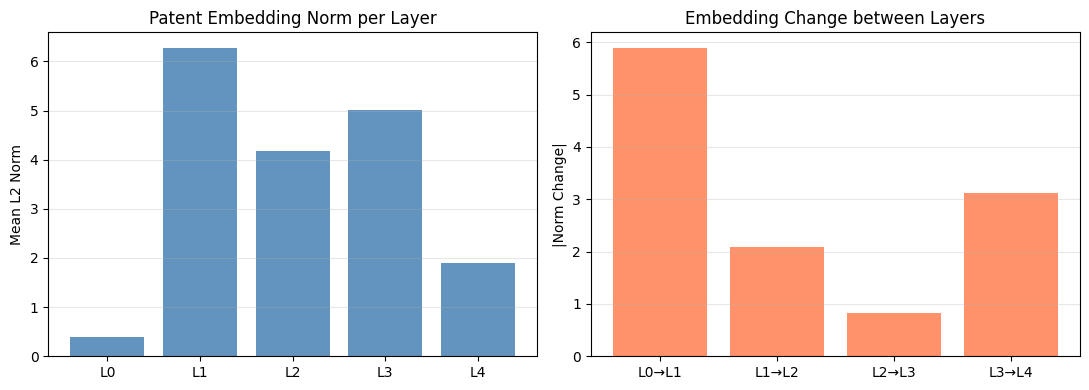

In [80]:
# Diagnostic — Embedding 변화량 (layer별 patent L2 norm)
# 모델 수정 없이 forward를 단계별로 수동 실행

import matplotlib.pyplot as plt
import numpy as np

@torch.no_grad()
def get_layer_snapshots(model, data):
    model.eval()
    x_pat = torch.cat([data['patent'].struct, data['patent'].x], dim=1)
    x = {
        'patent':  model.pat_proj(x_pat),
        'company': F.leaky_relu(model.co_proj(data['company'].x)),
        'ipc':     model.ipc_emb.weight,
    }
    snapshots = [x['patent'].cpu().clone()]  # L0: projection 직후
    for conv, bn, act in zip(model.convs[:3], model.bns, _CONV_ACTS):
        x_new = conv(x, data.edge_index_dict)
        x = {
            k: model.drop(act(bn[k](v.view(-1, model.hid))))
            if k in bn else model.drop(act(v))
            for k, v in x_new.items()
        }
        snapshots.append(x['patent'].cpu().clone())  # L1, L2, L3
    x_out = model.convs[3](x, data.edge_index_dict)
    snapshots.append(x_out['patent'].view(-1, model.out).cpu().clone())  # L4
    return snapshots

snapshots = get_layer_snapshots(model, data_d)

layer_norms = [s.norm(dim=1).mean().item() for s in snapshots]
delta_norms = [abs(layer_norms[i+1] - layer_norms[i]) for i in range(len(layer_norms)-1)]

print('Embedding norm per layer (patent):')
for i, n in enumerate(layer_norms):
    delta = f'  |Δ|={delta_norms[i]:.4f}' if i < len(delta_norms) else ''
    print(f'  L{i}: {n:.4f}{delta}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(len(layer_norms)), layer_norms, color='steelblue', alpha=0.85)
axes[0].set_xticks(range(len(layer_norms)))
axes[0].set_xticklabels([f'L{i}' for i in range(len(layer_norms))])
axes[0].set_ylabel('Mean L2 Norm')
axes[0].set_title('Patent Embedding Norm per Layer')
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(range(len(delta_norms)), delta_norms, color='coral', alpha=0.85)
axes[1].set_xticks(range(len(delta_norms)))
axes[1].set_xticklabels([f'L{i}→L{i+1}' for i in range(len(delta_norms))])
axes[1].set_ylabel('|Norm Change|')
axes[1].set_title('Embedding Change between Layers')
axes[1].grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


Val set에서 최적 threshold 탐색...

 Threshold  Precision     Recall         F1
---------------------------------------------
      0.05     0.5000     1.0000     0.6667
      0.10     0.5000     1.0000     0.6667
      0.15     0.5000     1.0000     0.6667
      0.20     0.5000     1.0000     0.6667
      0.25     0.5000     1.0000     0.6667
      0.30     0.5000     1.0000     0.6667
      0.35     0.5000     1.0000     0.6667
      0.40     0.5000     1.0000     0.6667
      0.45     0.5000     1.0000     0.6667
      0.50     0.5216     1.0000     0.6856
      0.55     0.5691     0.9655     0.7161
      0.60     0.6537     0.9241     0.7657
      0.65     0.8288     0.8345     0.8316
      0.70     0.9038     0.3241     0.4772
      0.75     0.0000     0.0000     0.0000
      0.80     0.0000     0.0000     0.0000
      0.85     0.0000     0.0000     0.0000
      0.90     0.0000     0.0000     0.0000
      0.95     0.0000     0.0000     0.0000

→ Best threshold: 0.65  (F1=0.8316)


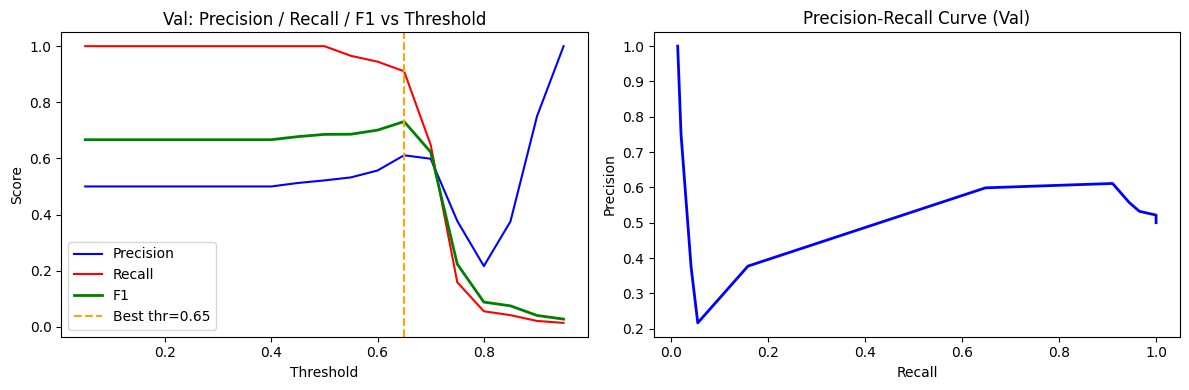


최종 선택 threshold: 0.65  (Val F1=0.8316)


In [81]:
# Cell 13-B — Threshold 튜닝 (Val set 기준)
print('Val set에서 최적 threshold 탐색...\n')
best_threshold, best_val_f1 = tune_threshold(model, data_d, va_e)

# 시각화: threshold vs F1 곡선
thrs, precs, recs, f1s = [], [], [], []
model.eval()
with torch.no_grad():
    h_val = model(data_d)['patent']
    dev   = h_val.device
    pos_l = (h_val[va_e[0]] * h_val[va_e[1]]).sum(1).cpu().numpy()
    rng_v = np.random.default_rng(99)
    neg_d = torch.tensor(rng_v.integers(0, len(pat_list), len(pos_l)), dtype=torch.long).to(dev)
    neg_l = (h_val[va_e[0]] * h_val[neg_d]).sum(1).cpu().numpy()
all_p  = 1 / (1 + np.exp(-np.concatenate([pos_l, neg_l])))
all_lb = np.array([1]*len(pos_l) + [0]*len(neg_l))

for thr in np.arange(0.05, 0.96, 0.05):
    preds = (all_p >= thr).astype(int)
    tp = int(((preds==1)&(all_lb==1)).sum())
    fp = int(((preds==1)&(all_lb==0)).sum())
    fn = int(((preds==0)&(all_lb==1)).sum())
    pr = tp/(tp+fp+1e-8); rc = tp/(tp+fn+1e-8)
    thrs.append(thr); precs.append(pr); recs.append(rc)
    f1s.append(2*pr*rc/(pr+rc+1e-8))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thrs, precs, 'b-', label='Precision')
axes[0].plot(thrs, recs,  'r-', label='Recall')
axes[0].plot(thrs, f1s,   'g-', label='F1', linewidth=2)
axes[0].axvline(best_threshold, color='orange', linestyle='--',
                label=f'Best thr={best_threshold:.2f}')
axes[0].set(title='Val: Precision / Recall / F1 vs Threshold',
            xlabel='Threshold', ylabel='Score')
axes[0].legend()

axes[1].plot(recs, precs, 'b-', linewidth=2)
axes[1].set(title='Precision-Recall Curve (Val)', xlabel='Recall', ylabel='Precision')
plt.tight_layout(); plt.show()
print(f'\n최종 선택 threshold: {best_threshold:.2f}  (Val F1={best_val_f1:.4f})')


모델                            AUROC    MRR    H@1    H@5   H@10   H@50  H@100  Med.R
----------------------------------------------------------------------------------
FAISS (baseline)             0.9301 0.1817 0.0606 0.3333 0.5152 0.6727 0.7758     10
Margin + case-split (이전)     0.9126 0.1301 0.0240 0.2420 0.3270 0.7520 0.7760     18
BCE + edge-split (현재) ★      0.8857 0.1195 0.0242 0.2121 0.3152 0.6485 0.7333     23


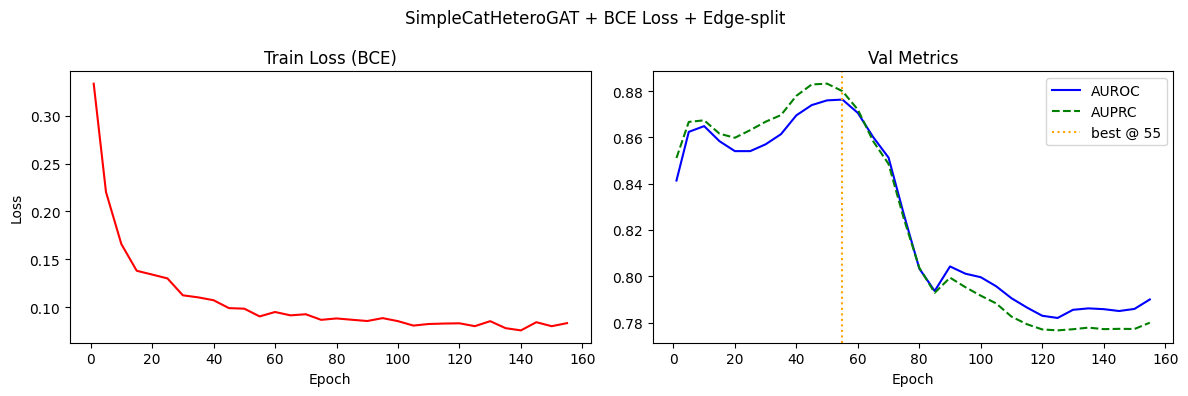


  Best val AUROC=0.8763 @ epoch 55
  Test  AUROC=0.8857  AUPRC=0.8548
  MRR=0.1195  H@10=0.3152  Median rank=23
  Best threshold (val F1): 0.65


In [82]:
# Cell 14 — 결과 비교표 + 학습 곡선

fr = faiss_baseline(test_edges)
faiss_auroc, faiss_auprc = fr[0], fr[1]
fr_ranks = faiss_ranking(test_edges)
faiss_r = {
    'MRR':   float(np.mean(1/fr_ranks)), 'H@1':  float(np.mean(fr_ranks<=1)),
    'H@5':   float(np.mean(fr_ranks<=5)),'H@10': float(np.mean(fr_ranks<=10)),
    'H@50':  float(np.mean(fr_ranks<=50)),'H@100':float(np.mean(fr_ranks<=100)),
    'Med':   float(np.median(fr_ranks)),
}
prev_r = {'MRR':0.1301,'H@1':0.024,'H@5':0.242,'H@10':0.327,
          'H@50':0.752,'H@100':0.776,'Med':18, 'auroc':0.9126}

W = 82
print(f'\n{"="*W}')
print(f'{"모델":<28} {"AUROC":>6} {"MRR":>6} {"H@1":>6} {"H@5":>6} {"H@10":>6} {"H@50":>6} {"H@100":>6} {"Med.R":>6}')
print(f'{"-"*W}')

def _row(name, auroc, r):
    print(f'{name:<28} {auroc:>6.4f} {r["MRR"]:>6.4f} {r["H@1"]:>6.4f} {r["H@5"]:>6.4f} '
          f'{r["H@10"]:>6.4f} {r["H@50"]:>6.4f} {r["H@100"]:>6.4f} {r["Med"]:>6.0f}')

_row('FAISS (baseline)',            faiss_auroc,          faiss_r)
_row('Margin + case-split (이전)',   prev_r['auroc'],      prev_r)
_row('BCE + edge-split (현재) ★',   bce_result['auroc'],  bce_result)
print(f'{"="*W}')

# 학습 곡선
eps, losses, aurocs, auprcs = zip(*history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(eps, losses, 'r-', linewidth=1.5)
ax1.set(title='Train Loss (BCE)', xlabel='Epoch', ylabel='Loss')
ax2.plot(eps, aurocs, 'b-', linewidth=1.5, label='AUROC')
ax2.plot(eps, auprcs, 'g--', linewidth=1.5, label='AUPRC')
ax2.axvline(best['epoch'], color='orange', linestyle=':', label=f'best @ {best["epoch"]}')
ax2.legend(); ax2.set(title='Val Metrics', xlabel='Epoch')
plt.suptitle('SimpleCatHeteroGAT + BCE Loss + Edge-split', fontsize=12)
plt.tight_layout(); plt.show()

print(f'\n  Best val AUROC={best["auroc"]:.4f} @ epoch {best["epoch"]}')
print(f'  Test  AUROC={bce_result["auroc"]:.4f}  AUPRC={bce_result["auprc"]:.4f}')
print(f'  MRR={bce_result["MRR"]:.4f}  H@10={bce_result["H@10"]:.4f}  Median rank={bce_result["Med"]:.0f}')
print(f'  Best threshold (val F1): {best_threshold:.2f}')

In [ ]:
# Cell 15 — Save checkpoint (viz_app 호환)
import os

CKPT_PATH = Path('phase3_simplecat_ckpt.pt')
DATA_PATH = Path('hetero_data.pt')

model.eval()
torch.save({
    # 모델
    'model_state':    best['state'],
    # 인덱스
    'pat_list':       pat_list,
    'co_list':        co_list,
    'ipc_list':       ipc_list,
    'pat_to_idx':     pat_to_idx,
    'ipc_to_idx':     ipc_to_idx,
    'co_to_idx':      co_to_idx,
    # 피처
    'pat_emb':        pat_emb,
    'pat_struct':     pat_struct,
    'co_feat':        co_feat,
    # 엣지 (case-level split)
    'sued_edges':   sued_edges.numpy(),
    'train_cases':  list(train_cases),
    'val_cases':    list(val_cases),
    'test_cases':   list(test_cases),
    # 데이터프레임
    'df_cit':         df_cit,
    'df_ipc':         df_ipc,
    'df_asgn':        df_asgn,
    # 결과
    'best_epoch':     best['epoch'],
    'best_threshold': best_threshold,   # val F1 최대 threshold
    'best_val_f1':    best_val_f1,
    'test_result':    bce_result,
}, CKPT_PATH)

torch.save(data.cpu(), DATA_PATH)

print('Saved:')
print(f'  {CKPT_PATH}  ({os.path.getsize(CKPT_PATH)/1e6:.1f} MB)')
print(f'  {DATA_PATH}  ({os.path.getsize(DATA_PATH)/1e6:.1f} MB)')
print(f'  best_threshold : {best_threshold:.2f}  (Val F1={best_val_f1:.4f})')
print(f'  test AUROC     : {bce_result["auroc"]:.4f}')
print(f'  test AUPRC     : {bce_result["auprc"]:.4f}')
print(f'  Median rank    : {bce_result["Med"]:.0f}')

Saved:
  phase3_simplecat_ckpt.pt  (18.2 MB)
  hetero_data.pt  (10.0 MB)
  best_threshold : 0.65  (Val F1=0.8316)
  test AUROC     : 0.8857
  test AUPRC     : 0.8548
  Median rank    : 23


: 